In [1]:
# Cell 1 — Setup
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

from src.regime import (build_regime_features, fit_hmm, predict_regimes,
                         label_regimes, add_regime_to_df, summarise_regimes)
from src.features import FEATURE_COLS
import joblib

df = pd.read_csv('../features/eurusd_labelled.csv', index_col=0, parse_dates=True)
print(f"Loaded: {df.shape}")

Loaded: (31628, 30)


In [2]:
# Cell 2 — Fit HMM regime classifier
X, feat_index = build_regime_features(df)
print(f"Regime feature matrix shape: {X.shape}")

hmm_model = fit_hmm(X, n_regimes=4, n_iter=200)
print(f"HMM fitted. Log-likelihood: {hmm_model.score(X):.2f}")

raw_labels = predict_regimes(hmm_model, X)
regime_map = label_regimes(hmm_model, X, raw_labels)
print(f"\nRegime mapping: {regime_map}")

Regime feature matrix shape: (31628, 5)
HMM fitted. Log-likelihood: -30220.49

Regime mapping: {np.int64(2): 'volatile_trend', np.int64(0): 'quiet_trend', 1: 'ranging', 3: 'ranging'}


In [3]:
# Cell 3 — Add regimes to DataFrame and summarise
df = add_regime_to_df(df, hmm_model, regime_map)
summarise_regimes(df)

# Save regime-labelled data
df.to_csv('../features/eurusd_regime_labelled.csv')
print("\nSaved to features/eurusd_regime_labelled.csv")


  Regime Distribution
  ranging              : 21,997  (69.5%)
  volatile_trend       : 6,867  (21.7%)
  quiet_trend          : 2,764  (8.7%)

Saved to features/eurusd_regime_labelled.csv


  Loading raw data files
  [OK] EURUSD 1H: 39,946 rows | 2020-01-01 → 2026-05-28
  [OK] EURUSD 4H: 39,946 rows | 2020-01-01 → 2026-05-28
  [OK] EURUSD Daily: 39,946 rows | 2020-01-01 → 2026-05-28
  [OK] DXY 1H: 39,946 rows | 2020-01-01 → 2026-05-28
  [OK] VIX Daily: 39,946 rows | 2020-01-01 → 2026-05-28
  [OK] US10Y Daily: 39,946 rows | 2020-01-01 → 2026-05-28
-------------------------------------------------------
  All files loaded successfully.


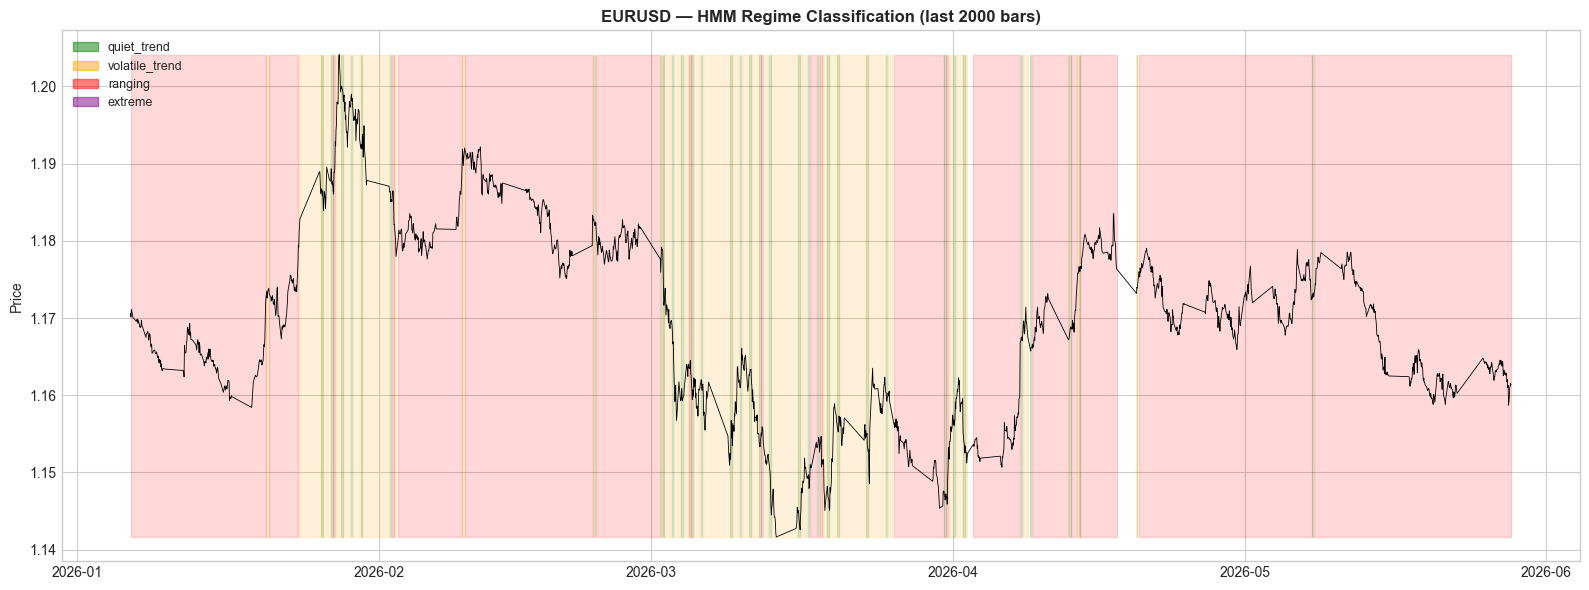

In [4]:
# Cell 4 — Visualise regimes on price chart
from src.data_loader import load_all_data
data = load_all_data()
eurusd_1h = data['eurusd_1h']

plot_df = eurusd_1h.join(df[['regime_name']], how='inner').dropna()
sample = plot_df.tail(2000)

colors = {'quiet_trend': 'green', 'volatile_trend': 'orange',
          'ranging': 'red', 'extreme': 'purple', 'unknown': 'gray'}

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(sample.index, sample['Close'], color='black', linewidth=0.6, zorder=2)

for regime, color in colors.items():
    mask = sample['regime_name'] == regime
    ax.fill_between(sample.index, sample['Close'].min(), sample['Close'].max(),
                    where=mask, alpha=0.15, color=color, label=regime)

ax.set_title('EURUSD — HMM Regime Classification (last 2000 bars)', fontweight='bold')
ax.set_ylabel('Price')
patches = [mpatches.Patch(color=c, label=r, alpha=0.5)
           for r, c in colors.items() if r != 'unknown']
ax.legend(handles=patches, fontsize=9, loc='upper left')
plt.tight_layout()
plt.savefig('../results/09_regime_chart.png', dpi=120, bbox_inches='tight')
plt.show()

In [5]:
# Cell 5 — Accuracy per regime (THE KEY DIAGNOSTIC)
from src.models import build_lgbm_baseline, build_xgb_baseline, build_catboost_baseline
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

class EnsembleClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self):
        self.lgbm = build_lgbm_baseline()
        self.xgb  = build_xgb_baseline()
        self.cat  = build_catboost_baseline()
    def fit(self, X, y):
        self.lgbm.fit(X, y); self.xgb.fit(X, y); self.cat.fit(X, y)
        self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        lp = self.lgbm.predict_proba(X)[:, 1]
        xp = self.xgb.predict_proba(X)[:, 1]
        cp = self.cat.predict_proba(X)[:, 1]
        avg = 0.45 * lp + 0.30 * xp + 0.25 * cp
        return np.column_stack([1 - avg, avg])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

X = df[FEATURE_COLS]
y = df['label_binary'].astype(int)
split_idx = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
df_test = df.iloc[split_idx:]

print("Training ensemble for regime analysis (2-3 min)...")
ens = EnsembleClassifier()
ens.fit(X_train, y_train)
probs = ens.predict_proba(X_test)[:, 1]
preds = (probs >= 0.5).astype(int)

print("\n" + "="*65)
print("  Accuracy per Regime — ALL signals")
print("="*65)
print(f"  {'Regime':<20} | {'Count':>6} | {'Accuracy':>9} | {'HC Signals':>10} | {'HC Acc':>7}")
print("-"*65)

regime_thresholds = {}
all_regimes = df_test['regime_name'].dropna().unique().tolist()
print(f"  Regimes found in test set: {all_regimes}")
for regime in all_regimes:
    mask = (df_test['regime_name'] == regime).values
    if mask.sum() < 10:
        continue
    acc = accuracy_score(y_test.values[mask], preds[mask])
    hc_mask = mask & ((probs >= 0.60) | (probs <= 0.40))
    hc_count = hc_mask.sum()
    hc_acc = accuracy_score(y_test.values[hc_mask],
                             preds[hc_mask]) if hc_count >= 10 else np.nan
    print(f"  {regime:<20} | {mask.sum():>6,} | {acc*100:>8.2f}% | "
          f"{hc_count:>10,} | "
          f"{'N/A' if np.isnan(hc_acc) else f'{hc_acc*100:.2f}%':>7}")
    regime_thresholds[regime] = acc

print("="*65)

Training ensemble for regime analysis (2-3 min)...

  Accuracy per Regime — ALL signals
  Regime               |  Count |  Accuracy | HC Signals |  HC Acc
-----------------------------------------------------------------
  Regimes found in test set: ['ranging', 'quiet_trend', 'volatile_trend']
  ranging              |  4,580 |    61.97% |        737 |  82.90%
  quiet_trend          |    438 |    73.29% |        374 |  78.61%
  volatile_trend       |  1,308 |    55.96% |          7 |     N/A


In [7]:
# Cell 6 — Regime-specific confidence thresholds
print("\n" + "="*65)
print("  Regime-Gated Threshold Recommendation")
print("="*65)
print()
print("  Based on accuracy per regime, use these gate thresholds:")
print()

for regime, acc in regime_thresholds.items():
    if acc >= 0.63:
        thresh = 0.58
        note = "strong edge — lower threshold, more signals"
    elif acc >= 0.58:
        thresh = 0.60
        note = "solid edge — standard threshold"
    else:
        thresh = 0.65
        note = "weak edge — raise threshold, fewer but better signals"
    print(f"  {regime:<20} : threshold = {thresh}  ({note})")

print()
print("  Update src/signal_gate.py:")
print("    REGIME_THRESHOLDS = {")
for regime, acc in regime_thresholds.items():
    if acc >= 0.63:
        thresh = 0.58
    elif acc >= 0.58:
        thresh = 0.60
    else:
        thresh = 0.65
    print(f"        '{regime}': {thresh},")
print("    }")

# Save HMM model
os.makedirs('../models', exist_ok=True)
joblib.dump(hmm_model,  '../models/hmm_regime.pkl')
joblib.dump(regime_map, '../models/regime_map.pkl')
print("\n[SAVED] models/hmm_regime.pkl  — HMM parameters (updates every retrain)")
print("[SAVED] models/regime_map.pkl  — label mapping (may be identical if same architecture)")
print("="*65)


  Regime-Gated Threshold Recommendation

  Based on accuracy per regime, use these gate thresholds:

  ranging              : threshold = 0.6  (solid edge — standard threshold)
  quiet_trend          : threshold = 0.58  (strong edge — lower threshold, more signals)
  volatile_trend       : threshold = 0.65  (weak edge — raise threshold, fewer but better signals)

  Update src/signal_gate.py:
    REGIME_THRESHOLDS = {
        'ranging': 0.6,
        'quiet_trend': 0.58,
        'volatile_trend': 0.65,
    }

[SAVED] models/hmm_regime.pkl  — HMM parameters (updates every retrain)
[SAVED] models/regime_map.pkl  — label mapping (may be identical if same architecture)
